In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib
import warnings

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    RocCurveDisplay
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

In [2]:
PROCESSED_PATH = "../data/processed/"
MODEL_PATH = "../models/"

os.makedirs(PROCESSED_PATH, exist_ok=True)
os.makedirs(MODEL_PATH, exist_ok=True)

In [3]:
play_features = pd.read_csv(
    PROCESSED_PATH + "play_level_features.csv",
    dtype={
        "PlayKey": "string",
        "GameID": "string"
    }
)

injury_enriched = pd.read_csv(
    PROCESSED_PATH + "injury_enriched_features.csv",
    dtype={"PlayKey": "string"}
)

print("Play features:", play_features.shape)
print("Injury records:", injury_enriched.shape)

display(play_features.head())

Play features: (267005, 34)
Injury records: (77, 41)


,PlayerKey,GameID,PlayKey,RosterPosition,PlayerDay,PlayerGame,StadiumType,FieldType,Temperature,Weather,...,y_max,duration,speed_mean,speed_std,acceleration_mean,acceleration_abs_mean,x_range,y_range,is_synthetic,temperature_category
0,26624,26624-1,26624-1-1,Quarterback,1,1,Outdoor,synthetic,63,Clear and warm,...,29.85,29.8,0.535753,0.607923,-0.000336,0.339262,7.13,6.23,1,Moderate
1,26624,26624-1,26624-1-2,Quarterback,1,1,Outdoor,synthetic,63,Clear and warm,...,29.96,25.9,0.849692,0.617141,0.041313,0.386486,10.18,2.61,1,Moderate
2,26624,26624-1,26624-1-3,Quarterback,1,1,Outdoor,synthetic,63,Clear and warm,...,29.63,29.5,0.331014,0.487729,0.043729,0.158983,4.33,3.89,1,Moderate
3,26624,26624-1,26624-1-4,Quarterback,1,1,Outdoor,synthetic,63,Clear and warm,...,27.71,12.6,0.523701,0.529241,0.075397,0.353175,3.09,3.08,1,Moderate
4,26624,26624-1,26624-1-5,Quarterback,1,1,Outdoor,synthetic,63,Clear and warm,...,26.41,25.9,0.970385,0.869971,0.049807,0.268340,20.47,4.48,1,Moderate


In [6]:
# Identify unique injured PlayKeys
injured_playkeys = set(
    injury_enriched["PlayKey"]
    .dropna()
    .unique()
)

print("Unique injured PlayKeys:", len(injured_playkeys))

# Create model dataset
model_data = play_features.copy()

# Verify unique PlayKeys
assert model_data["PlayKey"].is_unique, (
    "Duplicate PlayKeys found in play_features."
)

# Create classification target
model_data["recorded_injury_label"] = (
    model_data["PlayKey"]
    .isin(injured_playkeys)
    .astype(int)
)

print("\nModel dataset shape:", model_data.shape)

print("\nTarget distribution:")
print(model_data["recorded_injury_label"].value_counts())

display(model_data.head())

Unique injured PlayKeys: 76

Model dataset shape: (267005, 35)

Target distribution:
recorded_injury_label
0    266929
1        76
Name: count, dtype: int64


,PlayerKey,GameID,PlayKey,RosterPosition,PlayerDay,PlayerGame,StadiumType,FieldType,Temperature,Weather,...,duration,speed_mean,speed_std,acceleration_mean,acceleration_abs_mean,x_range,y_range,is_synthetic,temperature_category,recorded_injury_label
0,26624,26624-1,26624-1-1,Quarterback,1,1,Outdoor,synthetic,63,Clear and warm,...,29.8,0.535753,0.607923,-0.000336,0.339262,7.13,6.23,1,Moderate,0
1,26624,26624-1,26624-1-2,Quarterback,1,1,Outdoor,synthetic,63,Clear and warm,...,25.9,0.849692,0.617141,0.041313,0.386486,10.18,2.61,1,Moderate,0
2,26624,26624-1,26624-1-3,Quarterback,1,1,Outdoor,synthetic,63,Clear and warm,...,29.5,0.331014,0.487729,0.043729,0.158983,4.33,3.89,1,Moderate,0
3,26624,26624-1,26624-1-4,Quarterback,1,1,Outdoor,synthetic,63,Clear and warm,...,12.6,0.523701,0.529241,0.075397,0.353175,3.09,3.08,1,Moderate,0
4,26624,26624-1,26624-1-5,Quarterback,1,1,Outdoor,synthetic,63,Clear and warm,...,25.9,0.970385,0.869971,0.049807,0.268340,20.47,4.48,1,Moderate,0


In [7]:
numeric_features = [
    "Temperature",
    "tracking_points",
    "duration",
    "distance_total",
    "speed_mean",
    "speed_max",
    "speed_std",
    "acceleration_mean",
    "acceleration_abs_mean",
    "acceleration_abs_max",
    "x_range",
    "y_range"
]

categorical_features = [
    "FieldType",
    "StadiumType",
    "Weather",
    "PlayType",
    "Position",
    "PositionGroup",
    "RosterPosition",
    "temperature_category"
]

numeric_features = [
    c for c in numeric_features
    if c in model_data.columns
]

categorical_features = [
    c for c in categorical_features
    if c in model_data.columns
]

feature_columns = numeric_features + categorical_features

valid_rows = model_data["GameID"].notna()

X = model_data.loc[
    valid_rows, feature_columns
].copy().reset_index(drop=True)

y = model_data.loc[
    valid_rows, "recorded_injury_label"
].copy().reset_index(drop=True)

groups = model_data.loc[
    valid_rows, "GameID"
].copy().reset_index(drop=True)

X = X.replace([np.inf, -np.inf], np.nan)

print("X shape:", X.shape)
print("Positive records:", y.sum())
print("Negative records:", (y == 0).sum())
print("Unique games:", groups.nunique())

X shape: (267005, 20)
Positive records: 76
Negative records: 266929
Unique games: 5712


In [8]:
def create_logistic_model(num_cols, cat_cols):

    numeric_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]
    )

    categorical_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            (
                "encoder",
                OneHotEncoder(handle_unknown="ignore")
            )
        ]
    )

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, num_cols),
            ("cat", categorical_transformer, cat_cols)
        ]
    )

    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            (
                "classifier",
                LogisticRegression(
                    class_weight="balanced",
                    max_iter=1000,
                    solver="liblinear",
                    random_state=42
                )
            )
        ]
    )

    return model

In [9]:
def run_group_cv(X, y, groups, model, model_name):

    cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    oof_probability = np.full(len(y), np.nan)
    oof_prediction = np.full(len(y), -1)

    fold_results = []

    for fold, (train_idx, test_idx) in enumerate(
        cv.split(X, y, groups),
        start=1
    ):

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]

        train_groups = groups.iloc[train_idx]
        test_groups = groups.iloc[test_idx]

        # Confirm that no game occurs in both sets
        assert set(train_groups).isdisjoint(
            set(test_groups)
        )

        if y_train.nunique() < 2 or y_test.nunique() < 2:
            raise ValueError(
                f"Fold {fold} does not contain both classes. "
                "Inspect the distribution of positive labels across games."
            )

        model.fit(X_train, y_train)

        probabilities = model.predict_proba(X_test)[:, 1]
        predictions = (probabilities >= 0.5).astype(int)

        oof_probability[test_idx] = probabilities
        oof_prediction[test_idx] = predictions

        fold_results.append({
            "Model": model_name,
            "Fold": fold,
            "Train_Records": len(train_idx),
            "Test_Records": len(test_idx),
            "Train_Positive": int(y_train.sum()),
            "Test_Positive": int(y_test.sum()),
            "Train_Games": train_groups.nunique(),
            "Test_Games": test_groups.nunique(),
            "ROC_AUC": roc_auc_score(
                y_test, probabilities
            ),
            "PR_AUC": average_precision_score(
                y_test, probabilities
            ),
            "Precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_test, predictions, zero_division=0
            )
        })

        print(
            f"Fold {fold} completed | "
            f"Test positives: {y_test.sum()} | "
            f"PR-AUC: {fold_results[-1]['PR_AUC']:.6f}"
        )

    assert not np.isnan(oof_probability).any()
    assert (oof_prediction != -1).all()

    return (
        pd.DataFrame(fold_results),
        oof_probability,
        oof_prediction
    )

In [10]:
logistic_model = create_logistic_model(
    numeric_features,
    categorical_features
)

logistic_cv_results, logistic_oof_prob, logistic_oof_pred = (
    run_group_cv(
        X,
        y,
        groups,
        logistic_model,
        "Logistic Regression"
    )
)

display(logistic_cv_results)

Fold 1 completed | Test positives: 15 | PR-AUC: 0.000742
Fold 2 completed | Test positives: 16 | PR-AUC: 0.000618
Fold 3 completed | Test positives: 15 | PR-AUC: 0.000780
Fold 4 completed | Test positives: 15 | PR-AUC: 0.000715
Fold 5 completed | Test positives: 15 | PR-AUC: 0.001795


,Model,Fold,Train_Records,Test_Records,Train_Positive,Test_Positive,Train_Games,Test_Games,ROC_AUC,PR_AUC,Precision,Recall,F1
0,Logistic Regression,1,213604,53401,61,15,4571,1141,0.688895,0.000742,0.000622,0.400000,0.001242
1,Logistic Regression,2,213603,53402,60,16,4568,1144,0.625635,0.000618,0.000532,0.312500,0.001062
2,Logistic Regression,3,213605,53400,61,15,4570,1142,0.611873,0.000780,0.000477,0.333333,0.000953
3,Logistic Regression,4,213603,53402,61,15,4569,1143,0.580746,0.000715,0.000487,0.266667,0.000973
4,Logistic Regression,5,213605,53400,61,15,4570,1142,0.662844,0.001795,0.000528,0.333333,0.001054


In [11]:
logistic_cv_summary = pd.DataFrame({
    "Metric": [
        "ROC-AUC",
        "PR-AUC",
        "Precision",
        "Recall",
        "F1"
    ],
    "Mean_Fold_Score": [
        logistic_cv_results["ROC_AUC"].mean(),
        logistic_cv_results["PR_AUC"].mean(),
        logistic_cv_results["Precision"].mean(),
        logistic_cv_results["Recall"].mean(),
        logistic_cv_results["F1"].mean()
    ],
    "Std_Fold_Score": [
        logistic_cv_results["ROC_AUC"].std(),
        logistic_cv_results["PR_AUC"].std(),
        logistic_cv_results["Precision"].std(),
        logistic_cv_results["Recall"].std(),
        logistic_cv_results["F1"].std()
    ]
})

display(logistic_cv_summary)

print(
    "Pooled OOF ROC-AUC:",
    roc_auc_score(y, logistic_oof_prob)
)

print(
    "Pooled OOF PR-AUC:",
    average_precision_score(y, logistic_oof_prob)
)

print(
    "Overall positive prevalence:",
    y.mean()
)

,Metric,Mean_Fold_Score,Std_Fold_Score
0,ROC-AUC,0.633998,0.042547
1,PR-AUC,0.000930,0.000487
2,Precision,0.000529,0.000057
3,Recall,0.329167,0.048052
4,F1,0.001057,0.000114


Pooled OOF ROC-AUC: 0.6324357689438804
Pooled OOF PR-AUC: 0.0006330835469278366
Overall positive prevalence: 0.0002846388644407408


In [12]:
reduced_numeric_features = [
    col for col in numeric_features
    if col not in [
        "duration",
        "tracking_points"
    ]
]

reduced_features = (
    reduced_numeric_features + categorical_features
)

X_reduced = X[reduced_features].copy()

print("Original feature count:", len(feature_columns))
print("Reduced feature count:", len(reduced_features))

Original feature count: 20
Reduced feature count: 18


In [13]:
reduced_model = create_logistic_model(
    reduced_numeric_features,
    categorical_features
)

reduced_cv_results, reduced_oof_prob, reduced_oof_pred = (
    run_group_cv(
        X_reduced,
        y,
        groups,
        reduced_model,
        "Logistic Regression - Reduced"
    )
)

display(reduced_cv_results)

Fold 1 completed | Test positives: 15 | PR-AUC: 0.000725
Fold 2 completed | Test positives: 16 | PR-AUC: 0.000607
Fold 3 completed | Test positives: 15 | PR-AUC: 0.000749
Fold 4 completed | Test positives: 15 | PR-AUC: 0.000717
Fold 5 completed | Test positives: 15 | PR-AUC: 0.001683


,Model,Fold,Train_Records,Test_Records,Train_Positive,Test_Positive,Train_Games,Test_Games,ROC_AUC,PR_AUC,Precision,Recall,F1
0,Logistic Regression - Reduced,1,213604,53401,61,15,4571,1141,0.688671,0.000725,0.000619,0.400000,0.001236
1,Logistic Regression - Reduced,2,213603,53402,60,16,4568,1144,0.624253,0.000607,0.000528,0.312500,0.001055
2,Logistic Regression - Reduced,3,213605,53400,61,15,4570,1142,0.610245,0.000749,0.000475,0.333333,0.000948
3,Logistic Regression - Reduced,4,213603,53402,61,15,4569,1143,0.579612,0.000717,0.000481,0.266667,0.000960
4,Logistic Regression - Reduced,5,213605,53400,61,15,4570,1142,0.662400,0.001683,0.000524,0.333333,0.001046


In [14]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression - All Features",
        "Logistic Regression - Reduced Features"
    ],
    "Mean_ROC_AUC": [
        logistic_cv_results["ROC_AUC"].mean(),
        reduced_cv_results["ROC_AUC"].mean()
    ],
    "Mean_PR_AUC": [
        logistic_cv_results["PR_AUC"].mean(),
        reduced_cv_results["PR_AUC"].mean()
    ],
    "Pooled_PR_AUC": [
        average_precision_score(y, logistic_oof_prob),
        average_precision_score(y, reduced_oof_prob)
    ]
})

display(model_comparison)

,Model,Mean_ROC_AUC,Mean_PR_AUC,Pooled_PR_AUC
0,Logistic Regression - All Features,0.633998,0.000930,0.000633
1,Logistic Regression - Reduced Features,0.633036,0.000896,0.000618


In [15]:
try:
    from catboost import CatBoostClassifier
    CATBOOST_AVAILABLE = True
    print("CatBoost is installed.")

except ImportError:
    CATBOOST_AVAILABLE = False
    print("CatBoost is not installed.")
    print("Install it using: pip install catboost")

CatBoost is installed.


In [16]:
X_cat = X.copy()

# Convert categorical columns into strings
for col in categorical_features:
    X_cat[col] = (
        X_cat[col]
        .fillna("Missing")
        .astype(str)
    )

# Ensure numerical columns are numeric
for col in numeric_features:
    X_cat[col] = pd.to_numeric(
        X_cat[col],
        errors="coerce"
    )

display(X_cat.head())

,Temperature,tracking_points,duration,distance_total,speed_mean,speed_max,speed_std,acceleration_mean,acceleration_abs_mean,acceleration_abs_max,x_range,y_range,FieldType,StadiumType,Weather,PlayType,Position,PositionGroup,RosterPosition,temperature_category
0,63,299.0,29.8,16.83,0.535753,2.94,0.607923,-0.000336,0.339262,2.7,7.13,6.23,synthetic,Outdoor,Clear and warm,Pass,QB,QB,Quarterback,Moderate
1,63,260.0,25.9,23.42,0.849692,2.32,0.617141,0.041313,0.386486,2.8,10.18,2.61,synthetic,Outdoor,Clear and warm,Pass,QB,QB,Quarterback,Moderate
2,63,296.0,29.5,10.68,0.331014,1.46,0.487729,0.043729,0.158983,2.4,4.33,3.89,synthetic,Outdoor,Clear and warm,Rush,QB,QB,Quarterback,Moderate
3,63,127.0,12.6,6.86,0.523701,1.74,0.529241,0.075397,0.353175,2.0,3.09,3.08,synthetic,Outdoor,Clear and warm,Rush,QB,QB,Quarterback,Moderate
4,63,260.0,25.9,25.94,0.970385,2.67,0.869971,0.049807,0.268340,2.6,20.47,4.48,synthetic,Outdoor,Clear and warm,Pass,QB,QB,Quarterback,Moderate


In [17]:
def run_catboost_cv(X, y, groups):

    cv = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    oof_probability = np.full(len(y), np.nan)
    fold_results = []
    trained_models = []

    for fold, (train_idx, test_idx) in enumerate(
        cv.split(X, y, groups),
        start=1
    ):

        X_train = X.iloc[train_idx]
        X_test = X.iloc[test_idx]

        y_train = y.iloc[train_idx]
        y_test = y.iloc[test_idx]

        assert set(groups.iloc[train_idx]).isdisjoint(
            set(groups.iloc[test_idx])
        )

        model = CatBoostClassifier(
            iterations=300,
            depth=4,
            learning_rate=0.03,
            loss_function="Logloss",
            eval_metric="AUC",
            auto_class_weights="Balanced",
            random_seed=42 + fold,
            verbose=False,
            allow_writing_files=False,
            thread_count=-1
        )

        model.fit(
            X_train,
            y_train,
            cat_features=categorical_features
        )

        probabilities = model.predict_proba(
            X_test
        )[:, 1]

        predictions = (
            probabilities >= 0.5
        ).astype(int)

        oof_probability[test_idx] = probabilities

        fold_results.append({
            "Model": "CatBoost",
            "Fold": fold,
            "Test_Positive": int(y_test.sum()),
            "ROC_AUC": roc_auc_score(
                y_test, probabilities
            ),
            "PR_AUC": average_precision_score(
                y_test, probabilities
            ),
            "Precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_test, predictions, zero_division=0
            )
        })

        trained_models.append(model)

        print(
            f"CatBoost Fold {fold} completed | "
            f"PR-AUC: {fold_results[-1]['PR_AUC']:.6f}"
        )

    assert not np.isnan(oof_probability).any()

    return (
        pd.DataFrame(fold_results),
        oof_probability,
        trained_models
    )

In [18]:
if CATBOOST_AVAILABLE:

    catboost_cv_results, catboost_oof_prob, catboost_models = (
        run_catboost_cv(
            X_cat,
            y,
            groups
        )
    )

    display(catboost_cv_results)

else:
    print("Skipping CatBoost evaluation.")

CatBoost Fold 1 completed | PR-AUC: 0.000744
CatBoost Fold 2 completed | PR-AUC: 0.000958
CatBoost Fold 3 completed | PR-AUC: 0.000507
CatBoost Fold 4 completed | PR-AUC: 0.000494
CatBoost Fold 5 completed | PR-AUC: 0.000832


,Model,Fold,Test_Positive,ROC_AUC,PR_AUC,Precision,Recall,F1
0,CatBoost,1,15,0.515762,0.000744,0.000675,0.266667,0.001346
1,CatBoost,2,16,0.624234,0.000958,0.000380,0.125000,0.000757
2,CatBoost,3,15,0.606936,0.000507,0.000429,0.133333,0.000855
3,CatBoost,4,15,0.584764,0.000494,0.000379,0.133333,0.000756
4,CatBoost,5,15,0.630407,0.000832,0.000785,0.266667,0.001565


In [19]:
comparison_rows = [
    {
        "Model": "Logistic Regression - All Features",
        "Mean_ROC_AUC": logistic_cv_results["ROC_AUC"].mean(),
        "Mean_PR_AUC": logistic_cv_results["PR_AUC"].mean(),
        "Pooled_PR_AUC": average_precision_score(
            y, logistic_oof_prob
        )
    },
    {
        "Model": "Logistic Regression - Reduced",
        "Mean_ROC_AUC": reduced_cv_results["ROC_AUC"].mean(),
        "Mean_PR_AUC": reduced_cv_results["PR_AUC"].mean(),
        "Pooled_PR_AUC": average_precision_score(
            y, reduced_oof_prob
        )
    }
]

if CATBOOST_AVAILABLE:

    comparison_rows.append({
        "Model": "CatBoost",
        "Mean_ROC_AUC": catboost_cv_results["ROC_AUC"].mean(),
        "Mean_PR_AUC": catboost_cv_results["PR_AUC"].mean(),
        "Pooled_PR_AUC": average_precision_score(
            y, catboost_oof_prob
        )
    })

final_comparison = pd.DataFrame(comparison_rows)

display(
    final_comparison.sort_values(
        "Pooled_PR_AUC",
        ascending=False
    )
)

,Model,Mean_ROC_AUC,Mean_PR_AUC,Pooled_PR_AUC
0,Logistic Regression - All Features,0.633998,0.000930,0.000633
1,Logistic Regression - Reduced,0.633036,0.000896,0.000618
2,CatBoost,0.592421,0.000707,0.000507


In [20]:
thresholds_to_test = [
    0.01, 0.025, 0.05, 0.10,
    0.25, 0.50, 0.75
]

threshold_results = []

for threshold in thresholds_to_test:

    predictions = (
        logistic_oof_prob >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y, predictions, zero_division=0
        ),
        "F1": f1_score(
            y, predictions, zero_division=0
        ),
        "Predicted_Positive": int(
            predictions.sum()
        )
    })

threshold_results = pd.DataFrame(
    threshold_results
)

display(threshold_results)

,Threshold,Precision,Recall,F1,Predicted_Positive
0,0.010,0.000382,0.802632,0.000763,159723
1,0.025,0.000378,0.723684,0.000756,145384
2,0.050,0.000386,0.671053,0.000771,132200
3,0.100,0.000409,0.618421,0.000817,114916
4,0.250,0.000439,0.473684,0.000877,81988
5,0.500,0.000530,0.328947,0.001058,47201
6,0.750,0.000617,0.184211,0.001230,22683


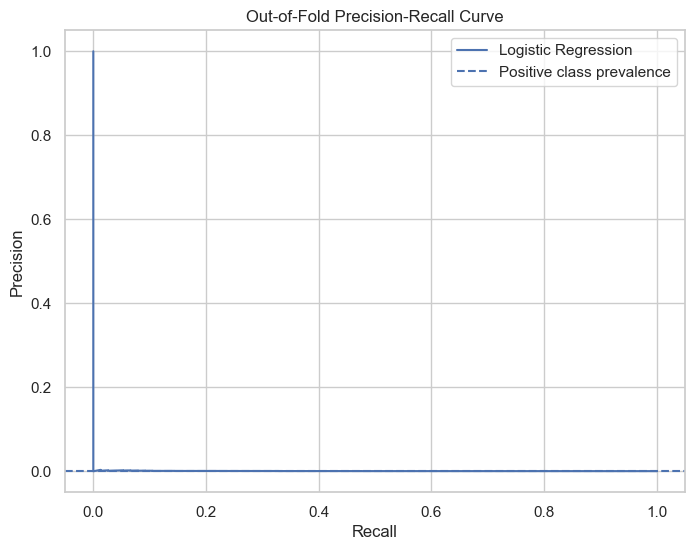

In [21]:
precision, recall, thresholds = precision_recall_curve(
    y,
    logistic_oof_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    label="Logistic Regression"
)

plt.axhline(
    y=y.mean(),
    linestyle="--",
    label="Positive class prevalence"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title("Out-of-Fold Precision-Recall Curve")

plt.legend()
plt.show()

[[219753  47176]
 [    51     25]]


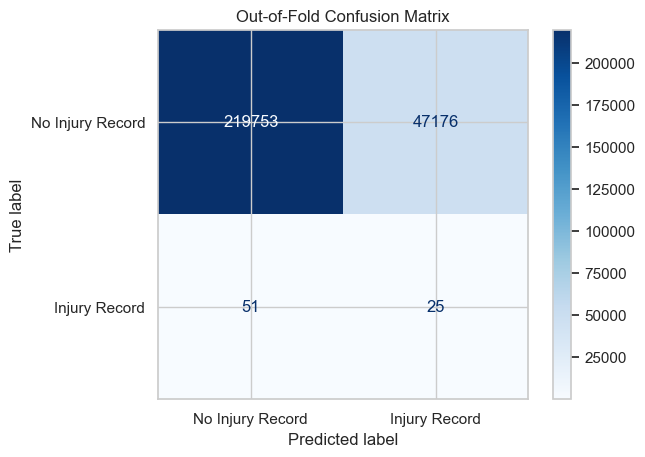

In [22]:
logistic_oof_pred = (
    logistic_oof_prob >= 0.5
).astype(int)

cm = confusion_matrix(
    y,
    logistic_oof_pred
)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "No Injury Record",
        "Injury Record"
    ]
).plot(cmap="Blues")

plt.title("Out-of-Fold Confusion Matrix")
plt.show()

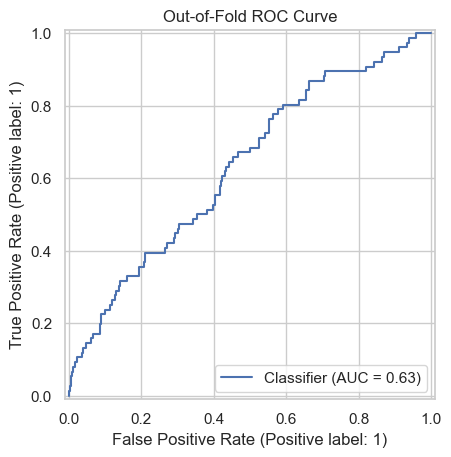

In [23]:
RocCurveDisplay.from_predictions(
    y,
    logistic_oof_prob
)

plt.title("Out-of-Fold ROC Curve")
plt.show()

In [24]:
final_logistic_model = create_logistic_model(
    numeric_features,
    categorical_features
)

# Fit on all available data for exploratory interpretation
final_logistic_model.fit(X, y)

preprocessor_fitted = (
    final_logistic_model.named_steps["preprocessor"]
)

feature_names = (
    preprocessor_fitted.get_feature_names_out()
)

coefficients = (
    final_logistic_model
    .named_steps["classifier"]
    .coef_[0]
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute_Importance": np.abs(coefficients)
})

importance_df = importance_df.sort_values(
    "Absolute_Importance",
    ascending=False
)

display(importance_df.head(20))

,Feature,Coefficient,Absolute_Importance
15,cat__StadiumType_Closed Dome,11.968829,11.968829
26,"cat__StadiumType_Indoor, Roof Closed",11.943072,11.943072
1,num__tracking_points,11.596275,11.596275
2,num__duration,-11.591451,11.591451
21,"cat__StadiumType_Domed, closed",8.909280,8.909280
58,"cat__Weather_Cloudy, 50% change of rain",8.229202,8.229202
70,cat__Weather_Indoor,7.722337,7.722337
24,cat__StadiumType_Indoor,7.502291,7.502291
22,"cat__StadiumType_Domed, open",-6.615576,6.615576
92,cat__Weather_Rain shower,6.349982,6.349982


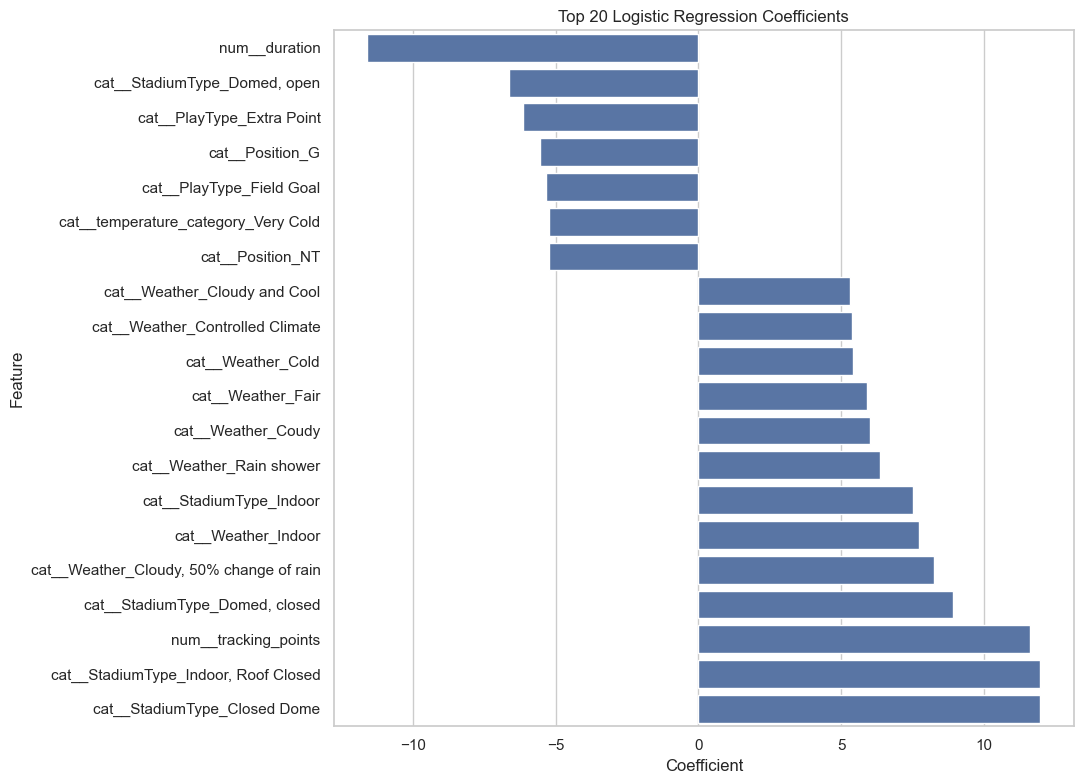

In [25]:
top_features = (
    importance_df.head(20)
    .sort_values("Coefficient")
)

plt.figure(figsize=(11, 8))

sns.barplot(
    data=top_features,
    x="Coefficient",
    y="Feature"
)

plt.title("Top 20 Logistic Regression Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

,Feature,Importance
3,distance_total,8.181608
0,Temperature,7.512667
11,y_range,7.294761
5,speed_max,7.192874
14,Weather,6.713715
10,x_range,6.470089
19,temperature_category,5.547457
6,speed_std,5.070945
9,acceleration_abs_max,5.025166
18,RosterPosition,4.893471


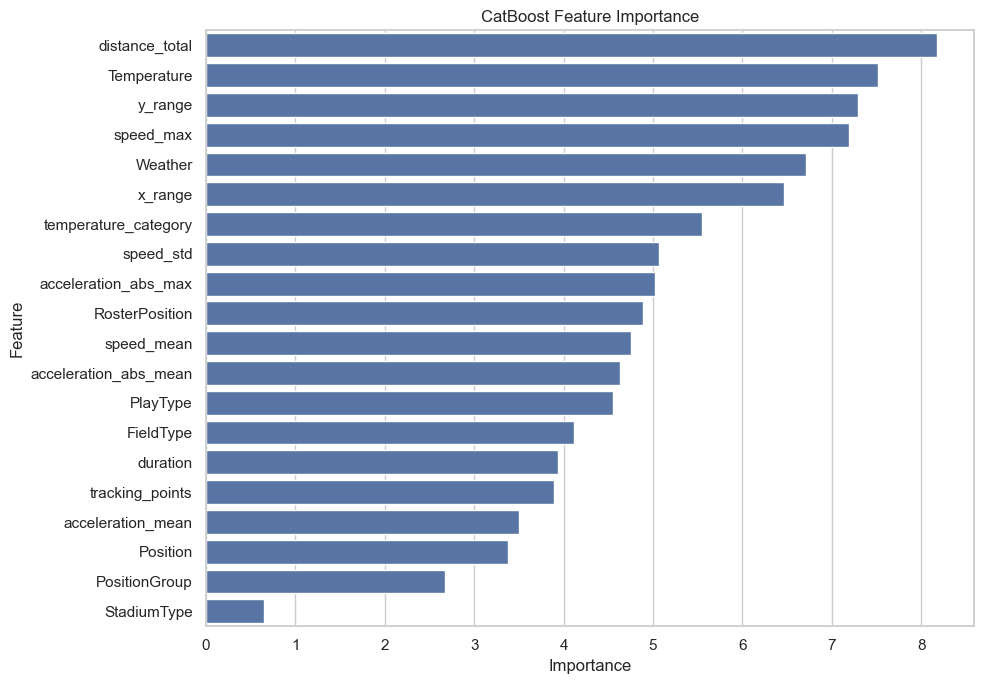

In [26]:
if CATBOOST_AVAILABLE:

    # Train one final model for exploratory interpretation
    final_catboost_model = CatBoostClassifier(
        iterations=300,
        depth=4,
        learning_rate=0.03,
        loss_function="Logloss",
        auto_class_weights="Balanced",
        random_seed=42,
        verbose=False,
        allow_writing_files=False,
        thread_count=-1
    )

    final_catboost_model.fit(
        X_cat,
        y,
        cat_features=categorical_features
    )

    catboost_importance = pd.DataFrame({
        "Feature": X_cat.columns,
        "Importance": final_catboost_model.feature_importances_
    }).sort_values(
        "Importance",
        ascending=False
    )

    display(catboost_importance.head(20))

    plt.figure(figsize=(10, 7))

    sns.barplot(
        data=catboost_importance.head(20),
        x="Importance",
        y="Feature"
    )

    plt.title("CatBoost Feature Importance")
    plt.tight_layout()
    plt.show()

else:
    print("CatBoost is unavailable. Skipping this section.")

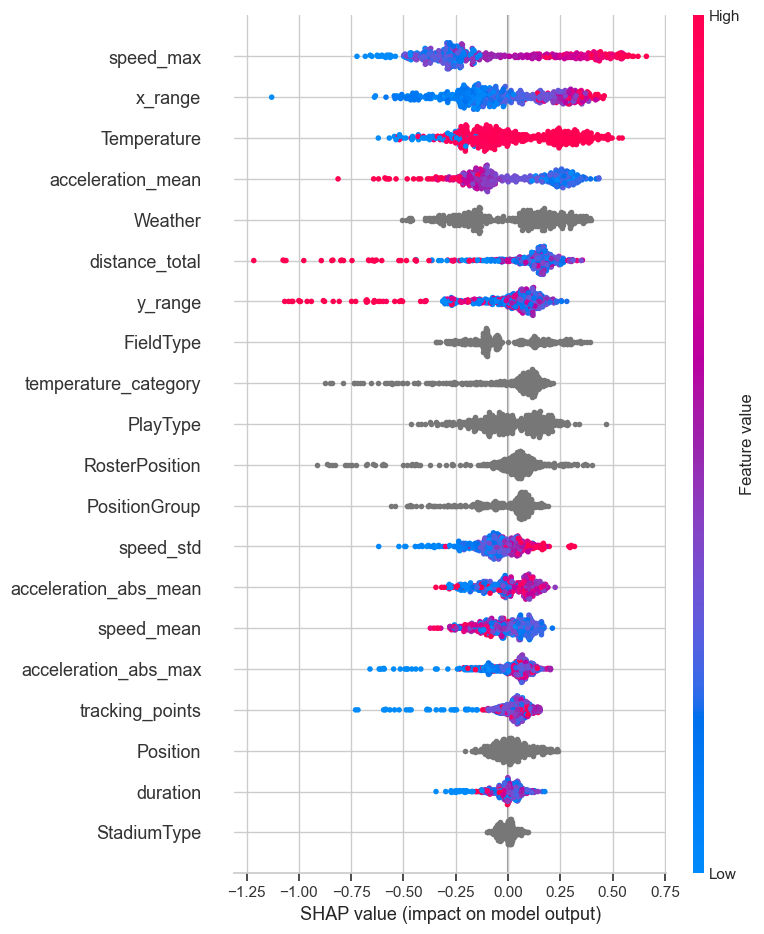

In [27]:
if CATBOOST_AVAILABLE:

    try:
        import shap

        # Sample observations to keep computation manageable
        X_shap = X_cat.sample(
            n=min(500, len(X_cat)),
            random_state=42
        )

        explainer = shap.TreeExplainer(
            final_catboost_model
        )

        shap_values = explainer.shap_values(
            X_shap
        )

        shap.summary_plot(
            shap_values,
            X_shap,
            show=True
        )

    except ImportError:
        print("Install SHAP using: pip install shap")

else:
    print("SHAP analysis requires CatBoost.")

In [28]:
logistic_cv_results.to_csv(
    PROCESSED_PATH + "logistic_cv_results.csv",
    index=False
)

reduced_cv_results.to_csv(
    PROCESSED_PATH + "reduced_logistic_cv_results.csv",
    index=False
)

if CATBOOST_AVAILABLE:
    catboost_cv_results.to_csv(
        PROCESSED_PATH + "catboost_cv_results.csv",
        index=False
    )

final_comparison.to_csv(
    PROCESSED_PATH + "model_comparison.csv",
    index=False
)

threshold_results.to_csv(
    PROCESSED_PATH + "threshold_analysis.csv",
    index=False
)

importance_df.to_csv(
    PROCESSED_PATH + "logistic_feature_importance.csv",
    index=False
)

print("Evaluation results saved successfully.")

Evaluation results saved successfully.


In [29]:
oof_predictions = pd.DataFrame({
    "PlayKey": model_data.loc[
        valid_rows, "PlayKey"
    ].reset_index(drop=True),

    "GameID": groups,

    "Actual_Label": y,

    "Logistic_Probability": logistic_oof_prob,

    "Reduced_Logistic_Probability": reduced_oof_prob
})

if CATBOOST_AVAILABLE:
    oof_predictions["CatBoost_Probability"] = (
        catboost_oof_prob
    )

oof_predictions.to_csv(
    PROCESSED_PATH + "oof_model_predictions.csv",
    index=False
)

print("Out-of-fold predictions saved.")

Out-of-fold predictions saved.


In [ ]:
joblib.dump(
    final_logistic_model,
    MODEL_PATH + "turfguard_final_logistic_model.pkl"
)

print("Final Logistic Regression model saved.")

Final Logistic Regression model saved.


: 